# 02 — Nettoyage, embeddings Sentence-BERT & topics BERTopic

1. **Nettoyage** des descriptions : minuscules, caractères spéciaux / LaTeX retirés, énoncés non anglais supprimés,
   quasi-doublons supprimés (lemmatisation + similarité cosinus TF-IDF).
2. **Embeddings** Sentence-BERT des descriptions nettoyées (mis en cache dans `data/embeddings/`).
3. **Clustering** BERTopic (UMAP → HDBSCAN) et confrontation des topics aux 8 tags cibles.
4. **TF-IDF par tag** (c-TF-IDF) sur la description et le code : termes caractéristiques de chaque tag.

Toute la logique est dans `src/preprocessing.py`, `src/embeddings.py`, `src/topics.py` et `src/class_tfidf.py` ;
le notebook orchestre et analyse.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from umap import UMAP

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import EMBEDDINGS_DIR, SEED, TARGET_TAGS, CleaningConfig, TopicConfig
from src.data import load_raw_dataset
from src.preprocessing import add_clean_text, assign_dup_groups, drop_near_duplicates, filter_language
from src.embeddings import (
    benchmark_encoder,
    compute_embeddings,
    embeddings_cache_path,
    get_device,
    load_encoder,
)
from src.class_tfidf import CODE_STOP_WORDS, CODE_TOKEN_PATTERN, class_tfidf, naive_class_tfidf, top_terms
from src.topics import build_topic_model

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("httpx", "httpx2", "huggingface_hub", "sentence_transformers"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 150)

CLEANING_CFG = CleaningConfig()
TOPIC_CFG = TopicConfig()

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 12:29:45.044000 40804 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Nettoyage

In [2]:
raw = load_raw_dataset()
english = filter_language(raw, CLEANING_CFG)
grouped = assign_dup_groups(add_clean_text(english, CLEANING_CFG), CLEANING_CFG)
df = drop_near_duplicates(grouped)

pd.Series(
    {
        "brut": len(raw),
        "retirés : non anglais": len(raw) - len(english),
        "retirés : quasi-doublons": len(grouped) - len(df),
        "final": len(df),
    }
).to_frame("n_exemples")

INFO src.preprocessing: Filtre langue : 4982 -> 4965 exemples


INFO src.preprocessing: Dédoublonnage : 4965 -> 4834 exemples


,n_exemples
brut,4982
retirés : non anglais,17
retirés : quasi-doublons,131
final,4834


In [3]:
non_english = raw.index.difference(english.index)
raw.loc[non_english, CLEANING_CFG.text_column].str[:100].to_frame("énoncés retirés (non anglais)").head()

,énoncés retirés (non anglais)
sample_id,
1449,"Как известно, в теплую погоду многие жители крупных городов пользуются сервисами городского велопрок"
1859,"В самолёте есть n рядов мест. Если смотреть на ряды сверху, то в каждом ряду есть 3 места слева, зат"
2008,Основой любой социальной сети является отношение дружбы между двумя пользователями в том или ином см
2185,"Родители Васи хотят, чтобы он как можно лучше учился. Поэтому если он получает подряд три положитель"
2498,"Прошло много лет, и на вечеринке снова встретились n друзей. С момента последней встречи техника шаг"


In [4]:
example = df.index[0]
print("BRUT      :", raw.at[example, CLEANING_CFG.text_column][:300])
print("\nNETTOYÉ   :", df.at[example, "text_clean"][:300])
print("\nLEMMATISÉ :", df.at[example, "text_lemma"][:300])

BRUT      : Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one integer $$$\frac{a + b}{2}$$$ rounded up instead.You should perform the given operation $$$n - 1$$$ times

NETTOYÉ   : numbers 1 2 3 dots n each integer from 1 to n once are written on a board in one operation you can erase any two numbers a and b from the board and write one integer frac a b 2 rounded up instead you should perform the given operation n 1 times and make the resulting number that will be left on the 

LEMMATISÉ : number 1 2 3 dot n each integer from 1 to n once are written on a board in one operation you can erase any two number a and b from the board and write one integer frac a b 2 rounded up instead you should perform the given operation n 1 time and make the resulting number that will be left on the boar


Le texte **lemmatisé** sert uniquement à détecter les quasi-doublons (il rapproche *trees* / *tree*, *numbers* / *number*).
Les embeddings sont calculés sur le texte **nettoyé non lemmatisé** : Sentence-BERT est entraîné sur du langage naturel,
la lemmatisation lui ferait perdre de l'information syntaxique.

In [5]:
group_sizes = grouped["dup_group"].value_counts()
print(f"{(group_sizes > 1).sum()} groupes de quasi-doublons, tailles : {group_sizes[group_sizes > 1].value_counts().to_dict()}")

# Exemples : exemple conservé vs exemple(s) retiré(s) du même groupe
for group in group_sizes[group_sizes > 1].index[:3]:
    members = grouped[grouped["dup_group"] == group].sort_index()
    for k, row in members.iterrows():
        status = "gardé " if k in df.index else "retiré"
        print(f"[{status}] [{k}] tags={row['tags']}\n    {row[CLEANING_CFG.text_column][:150]}")
    print()

109 groupes de quasi-doublons, tailles : {2: 101, 3: 5, 12: 1, 7: 1, 4: 1}
[gardé ] [329] tags=['implementation']
    You are given a bracket sequence $$$s$$$ consisting of $$$n$$$ opening '(' and closing ')' brackets.A regular bracket sequence is a bracket sequence t
[retiré] [343] tags=['implementation']
    A bracket sequence is a string containing only characters "(" and ")".A regular bracket sequence is a bracket sequence that can be transformed into a 
[retiré] [807] tags=['greedy']
    A bracket sequence is called regular if it is possible to obtain correct arithmetic expression by inserting characters «+» and «1» into this sequence.
[retiré] [1749] tags=['greedy']
    A bracket sequence is a string containing only characters "(" and ")". A regular bracket sequence is a bracket sequence that can be transformed into a
[retiré] [2261] tags=['dp', 'greedy', 'constructive algorithms', 'sortings', 'data structures', 'strings']
    This is yet another problem dealing with regular brac

In [6]:
lengths = df["text_clean"].str.split().str.len()
lengths.describe().round(0).to_frame("n_mots (texte nettoyé)").T

,count,mean,std,min,25%,50%,75%,max
n_mots (texte nettoyé),4834.0,174.0,82.0,11.0,116.0,161.0,219.0,693.0


## 2. Embeddings Sentence-BERT

Modèle : `{TOPIC_CFG.embedding_model}` (défini dans `TopicConfig`). Le calcul est fait une fois puis mis en cache.

In [7]:
encoder = load_encoder(TOPIC_CFG.embedding_model)
texts = df["text_clean"].tolist()

n_tokens = pd.Series([len(ids) for ids in encoder.tokenizer(texts)["input_ids"]])
print(f"device={get_device()} | max_seq_length={encoder.max_seq_length} | dim={encoder.get_sentence_embedding_dimension()}")
print(f"Textes tronqués : {(n_tokens > encoder.max_seq_length).mean():.1%} (médiane {n_tokens.median():.0f} tokens)")

# Estimation avant calcul complet : benchmark sur un échantillon
sample = df["text_clean"].sample(256, random_state=SEED).tolist()
per_text = benchmark_encoder(encoder, sample, TOPIC_CFG.batch_size)
print(f"{per_text * 1000:.1f} ms/texte -> estimation {per_text * len(texts):.0f} s pour {len(texts)} textes")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12044.60it/s]

WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (396 > 384). Running this sequence through the model will result in indexing errors


device=mps | max_seq_length=384 | dim=768
Textes tronqués : 2.9% (médiane 173 tokens)


17.0 ms/texte -> estimation 82 s pour 4834 textes


In [8]:
cache_path = embeddings_cache_path(EMBEDDINGS_DIR, TOPIC_CFG.embedding_model, CLEANING_CFG.text_column)
embeddings = compute_embeddings(
    texts, df.index.to_numpy(), encoder, cache_path, TOPIC_CFG.embedding_model, TOPIC_CFG.batch_size
)
print(cache_path.relative_to(ROOT), embeddings.shape)

INFO src.embeddings: Embeddings chargés depuis /Users/ramzi/Documents/illuin-test/data/embeddings/all-mpnet-base-v2__prob_desc_description.npz


data/embeddings/all-mpnet-base-v2__prob_desc_description.npz (4834, 768)


## 3. Clustering BERTopic (UMAP + HDBSCAN)

In [9]:
topic_model = build_topic_model(TOPIC_CFG)
topics, _ = topic_model.fit_transform(texts, embeddings)
df["topic"] = topics

info = topic_model.get_topic_info()
n_topics = (info["Topic"] != -1).sum()
print(f"{n_topics} topics | outliers HDBSCAN (topic -1) : {(df['topic'] == -1).mean():.1%}")
info.head(20)[["Topic", "Count", "Name"]]

61 topics | outliers HDBSCAN (topic -1) : 35.1%


,Topic,Count,Name
0,-1,1696,-1_number_th_time_cell
1,0,499,0_string_letters_strings_characters
2,1,287,1_tree_vertices_vertex_graph
3,2,151,2_permutation_permutations_permutation length_elements
4,3,120,3_buy_coins_price_shop
5,4,117,4_array_operation_operations_le
6,5,113,5_roads_city_cities_road
7,6,110,6_digits_digit_number_numbers
8,7,89,7_cards_card_player_game
9,8,77,8_contest_problems_rating_exam


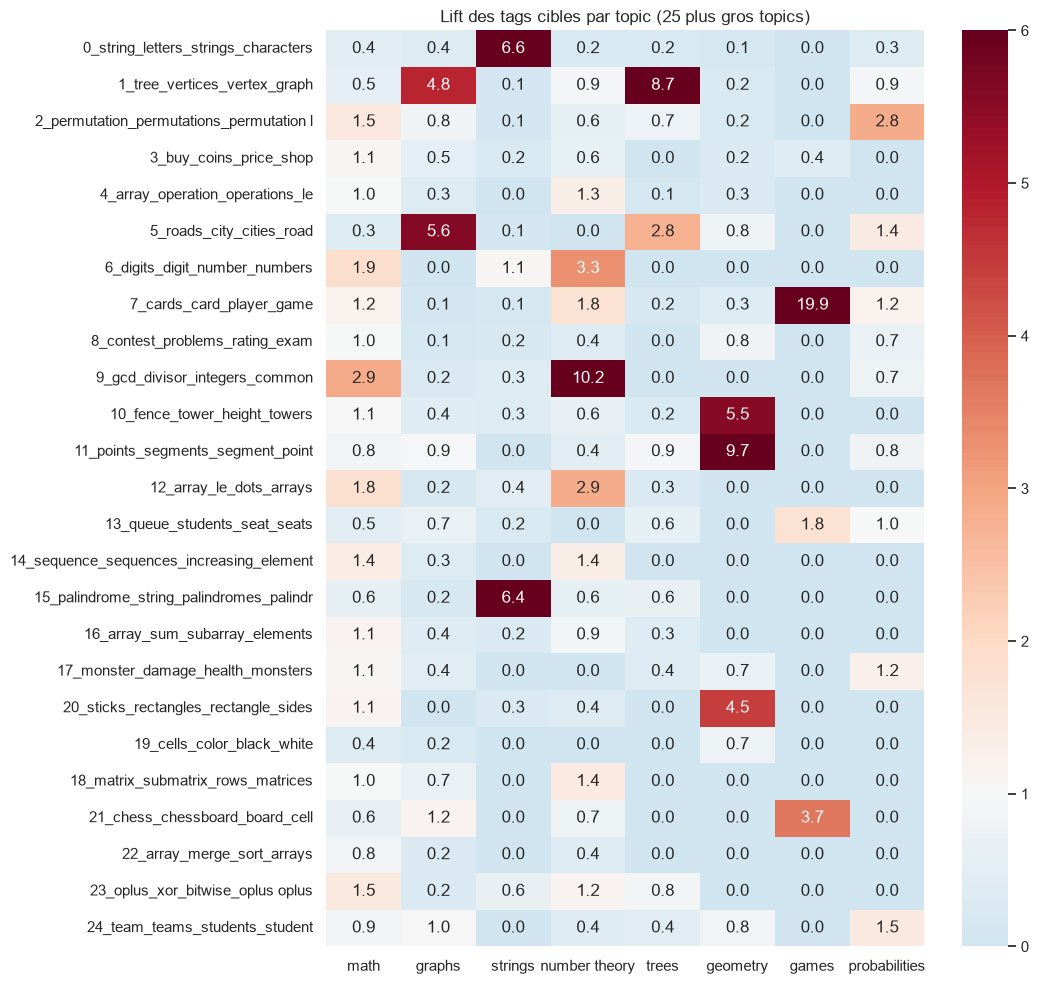

In [10]:
Y = pd.DataFrame({t: df["tags"].apply(lambda ts, t=t: t in ts) for t in TARGET_TAGS}).astype(int)

# Part de chaque tag cible dans chaque topic, rapportée à sa prévalence globale (lift > 1 = sur-représenté)
clustered = df["topic"] != -1
share = Y[clustered].groupby(df.loc[clustered, "topic"]).mean()
lift = share / Y.mean()
top_topics = df.loc[clustered, "topic"].value_counts().head(25).index

labels = [topic_model.get_topic_info(t)["Name"].iloc[0][:40] for t in top_topics]
fig, ax = plt.subplots(figsize=(11, 10))
sns.heatmap(lift.loc[top_topics].set_axis(labels), cmap="RdBu_r", center=1, vmax=6, annot=True, fmt=".1f", ax=ax)
ax.set(title="Lift des tags cibles par topic (25 plus gros topics)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

### Proportion de chaque tag cible par cluster

Pour chaque cluster BERTopic (outliers `-1` inclus) : part des exercices du cluster portant chaque tag cible.
Multi-label : une ligne ne somme pas à 100 %, d'où la colonne « aucun tag cible ».

In [11]:
proportions = Y.groupby(df["topic"]).mean()
proportions["aucun tag cible"] = (Y.sum(axis=1) == 0).groupby(df["topic"]).mean()
proportions.insert(0, "n", df["topic"].value_counts())
proportions.insert(0, "nom", info.set_index("Topic")["Name"].str[:45])

pct_cols = TARGET_TAGS + ["aucun tag cible"]
(
    proportions.sort_values("n", ascending=False)
    .style.format("{:.0%}", subset=pct_cols)
    .background_gradient(cmap="Reds", subset=TARGET_TAGS, vmin=0, vmax=1)
)

,nom,n,math,graphs,strings,number theory,trees,geometry,games,probabilities,aucun tag cible
topic,,,,,,,,,,,
-1,-1_number_th_time_cell,1696,30%,9%,3%,6%,4%,4%,1%,2%,53%
0,0_string_letters_strings_characters,499,12%,4%,56%,2%,1%,0%,0%,1%,33%
1,1_tree_vertices_vertex_graph,287,15%,53%,1%,6%,56%,1%,0%,2%,8%
2,2_permutation_permutations_permutation length,151,44%,9%,1%,4%,5%,1%,0%,5%,48%
3,3_buy_coins_price_shop,120,31%,6%,2%,4%,0%,1%,1%,0%,61%
4,4_array_operation_operations_le,117,28%,3%,0%,9%,1%,1%,0%,0%,69%
5,5_roads_city_cities_road,113,10%,61%,1%,0%,18%,3%,0%,3%,22%
6,6_digits_digit_number_numbers,110,54%,0%,9%,23%,0%,0%,0%,0%,36%
7,7_cards_card_player_game,89,35%,1%,1%,12%,1%,1%,42%,2%,33%


In [12]:
# Pour chaque tag cible : topic qui en contient le plus d'exemples, et dispersion du tag entre topics.
# (Le max de précision seul sélectionnerait des micro-topics peu représentatifs.)
tag_counts_by_topic = Y.groupby(df["topic"]).sum()
rows = []
for tag in TARGET_TAGS:
    counts = tag_counts_by_topic[tag].drop(-1).sort_values(ascending=False)
    best = counts.index[0]
    rows.append(
        {
            "tag": tag,
            "topic principal": topic_model.get_topic_info(best)["Name"].iloc[0][:45],
            "précision": share.at[best, tag],
            "rappel": counts.iloc[0] / Y[tag].sum(),
            "n topics pour 50 % du tag": int((counts.cumsum() / Y[tag].sum() < 0.5).sum() + 1),
            "part en outliers": tag_counts_by_topic.at[-1, tag] / Y[tag].sum(),
        }
    )
pd.DataFrame(rows).set_index("tag").round(2)

,topic principal,précision,rappel,n topics pour 50 % du tag,part en outliers
tag,,,,,
math,2_permutation_permutations_permutation length,0.44,0.05,27,0.37
graphs,1_tree_vertices_vertex_graph,0.53,0.28,6,0.29
strings,0_string_letters_strings_characters,0.56,0.68,1,0.11
number theory,9_gcd_divisor_integers_common,0.71,0.15,12,0.31
trees,1_tree_vertices_vertex_graph,0.56,0.52,1,0.21
geometry,11_points_segments_segment_point,0.32,0.14,10,0.40
games,7_cards_card_player_game,0.42,0.37,2,0.17
probabilities,2_permutation_permutations_permutation length,0.05,0.09,22,0.46


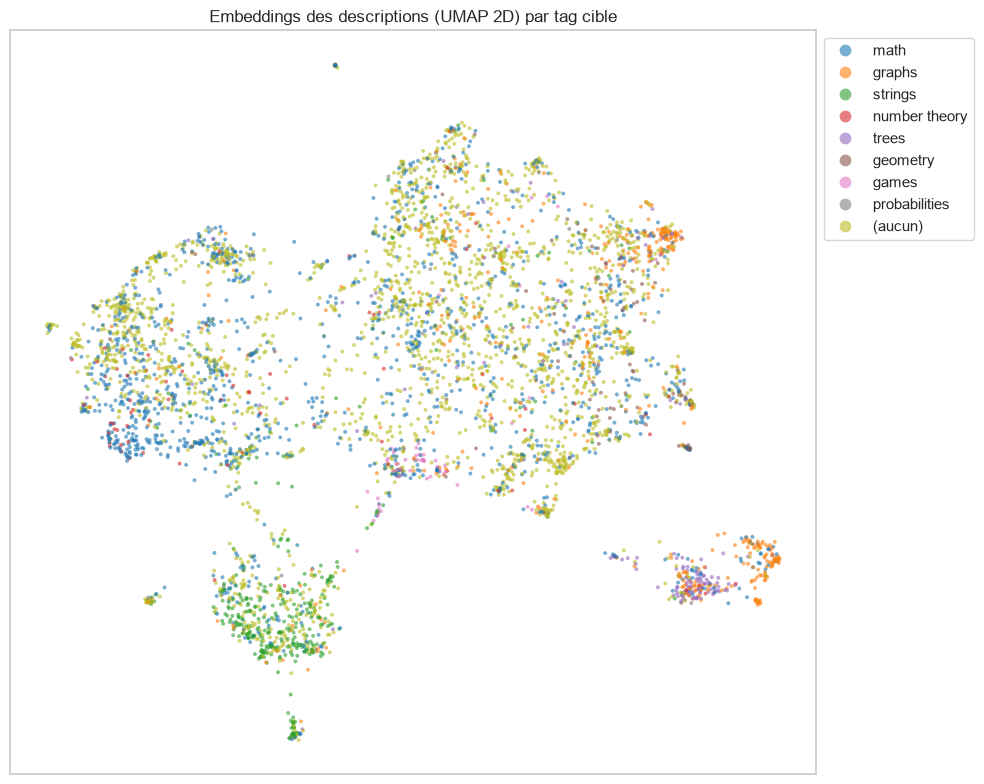

In [13]:
# Projection 2D (UMAP, seed fixe) colorée par tag cible principal, pour juger la séparabilité visuelle
coords = UMAP(n_neighbors=15, n_components=2, metric="cosine", random_state=SEED).fit_transform(embeddings)
main_tag = Y.idxmax(axis=1).where(Y.sum(axis=1) > 0, "(aucun)")

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=main_tag, hue_order=TARGET_TAGS + ["(aucun)"],
                palette="tab10", s=8, alpha=0.6, linewidth=0, ax=ax)
ax.set(title="Embeddings des descriptions (UMAP 2D) par tag cible", xticks=[], yticks=[])
ax.legend(markerscale=3, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 4. TF-IDF par tag : quels mots caractérisent chaque tag ?

Démarche inverse de BERTopic : au lieu de regrouper les énoncés puis de décrire les groupes, on part des **tags** et on
cherche les termes qui les caractérisent. C'est fait pour **deux colonnes** (`description` et `source_code`)
et pour les **8 tags cibles**, plus un groupe « aucun tag cible » qui sert de référence.

**Principe (c-TF-IDF)** : tous les textes d'un même tag sont concaténés en un seul document de classe, sur lequel on
calcule une TF-IDF.

**Description lemmatisée** (`text_lemma`) : sans lemmatisation, les formes d'un même mot (*string* / *strings*,
*vertex* / *vertices*) occupent des places distinctes dans le classement et se partagent le score. Le **code** n'est pas
lemmatisé : le lemmatiseur WordNet altérerait les identifiants (`nodes`, `primes`…).

> Analyse exploratoire, faite sur tout le jeu nettoyé. Pour une feature de modèle, le vocabulaire et l'IDF devraient être
> appris sur le train uniquement.

In [14]:
# Version naïve : TF-IDF classique sur les 9 documents de classe (description)
top_terms(naive_class_tfidf(df["text_lemma"], Y, stop_words="english"), 10)

,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
rang,,,,,,,,,
1,number,vertex,string,number,vertex,point,player,probability,number
2,integer,number,letter,integer,tree,polygon,game,number,ha
3,array,road,number,array,number,coordinate,turn,value,array
4,ha,edge,character,given,node,segment,play,integer,integer
5,given,city,length,le,edge,ha,card,ha,th
6,element,graph,substring,positive,path,number,number,game,time
7,time,ha,given,ha,ha,time,alice,expected,cell
8,operation,cell,example,gcd,city,plane,ha,th,sequence
9,th,tree,word,element,given,given,make,want,given


**Pourquoi la version naïve ne suffit pas.**
- **IDF presque plate** : avec seulement 9 documents, un mot présent dans les 9 (« number », « array », « given ») garde une
  IDF quasi identique aux autres. Ce sont donc les mots les plus **fréquents** qui ressortent, pas les plus **caractéristiques**.
- **Templates sur-pondérés** : sur le code, c'est pire, car un template de fast-IO copié dans des centaines de solutions écrase
  tout le reste.

**Version retenue** (`src/class_tfidf.py`) :

`score(terme, tag) = part des exercices du tag contenant le terme × log(N / nb d'exercices contenant le terme)`

- La **TF** reste celle du document de classe, mais chaque exercice compte au plus **une fois** par terme : un template répété
  ne pèse plus plus lourd qu'un mot utilisé une fois.
- L'**IDF** est calculée sur les ~4 800 exercices, ce qui pénalise réellement les termes omniprésents.
- **Code** : mots-clés Python et tokens d'entrées/sorties (`sys`, `stdin`, `print`…) exclus. Les fonctions natives
  informatives (`pow`, `ord`, `abs`…) sont conservées.

In [15]:
desc_scores = class_tfidf(df["text_lemma"], Y, stop_words="english", ngram_range=(1, 2))
top_terms(desc_scores, 15)

,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
rang,,,,,,,,,
1,integer,connected,string,divisor,tree,plane,play optimally,probability,th
2,positive,graph,letter,common divisor,vertex,point,optimally,expected,time
3,positive integer,edge,lowercase,greatest,connected,coordinate,player,expected value,want
4,array,vertex,given string,greatest common,path,angle,turn,random,ha
5,value,undirected,character,positive integer,edge,lie,play,randomly,order
6,example,path,substring,positive,graph,polygon,win,calculate expected,possible
7,given,road,string length,common,undirected,area,game,equiprobably,minimum
8,equal,way,length,gcd,tree vertex,line,loses,value,help
9,sum,vertex edge,string consisting,integer,root,parallel,player play,expected number,integer


In [16]:
code_scores = class_tfidf(
    df["source_code"], Y, token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS
)
top_terms(code_scores, 15)

,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
rang,,,,,,,,,
1,math,pop,len,gcd,pop,x1,Alice,pow,list
2,ans,append,ord,math,append,y1,Bob,random,max
3,list,collections,join,10,node,x2,First,10,len
4,10,add,strip,pow,parent,y2,Second,998244353,append
5,max,join,NO,list,add,math,win,float,ans
6,min,len,YES,ans,dfs,points,max,ans,min
7,str,set,str,append,len,float,count,tmp,str
8,append,str,count,str,__init__,abs,list,math,join
9,len,deque,set,len,read,pi,odd,sum,sort


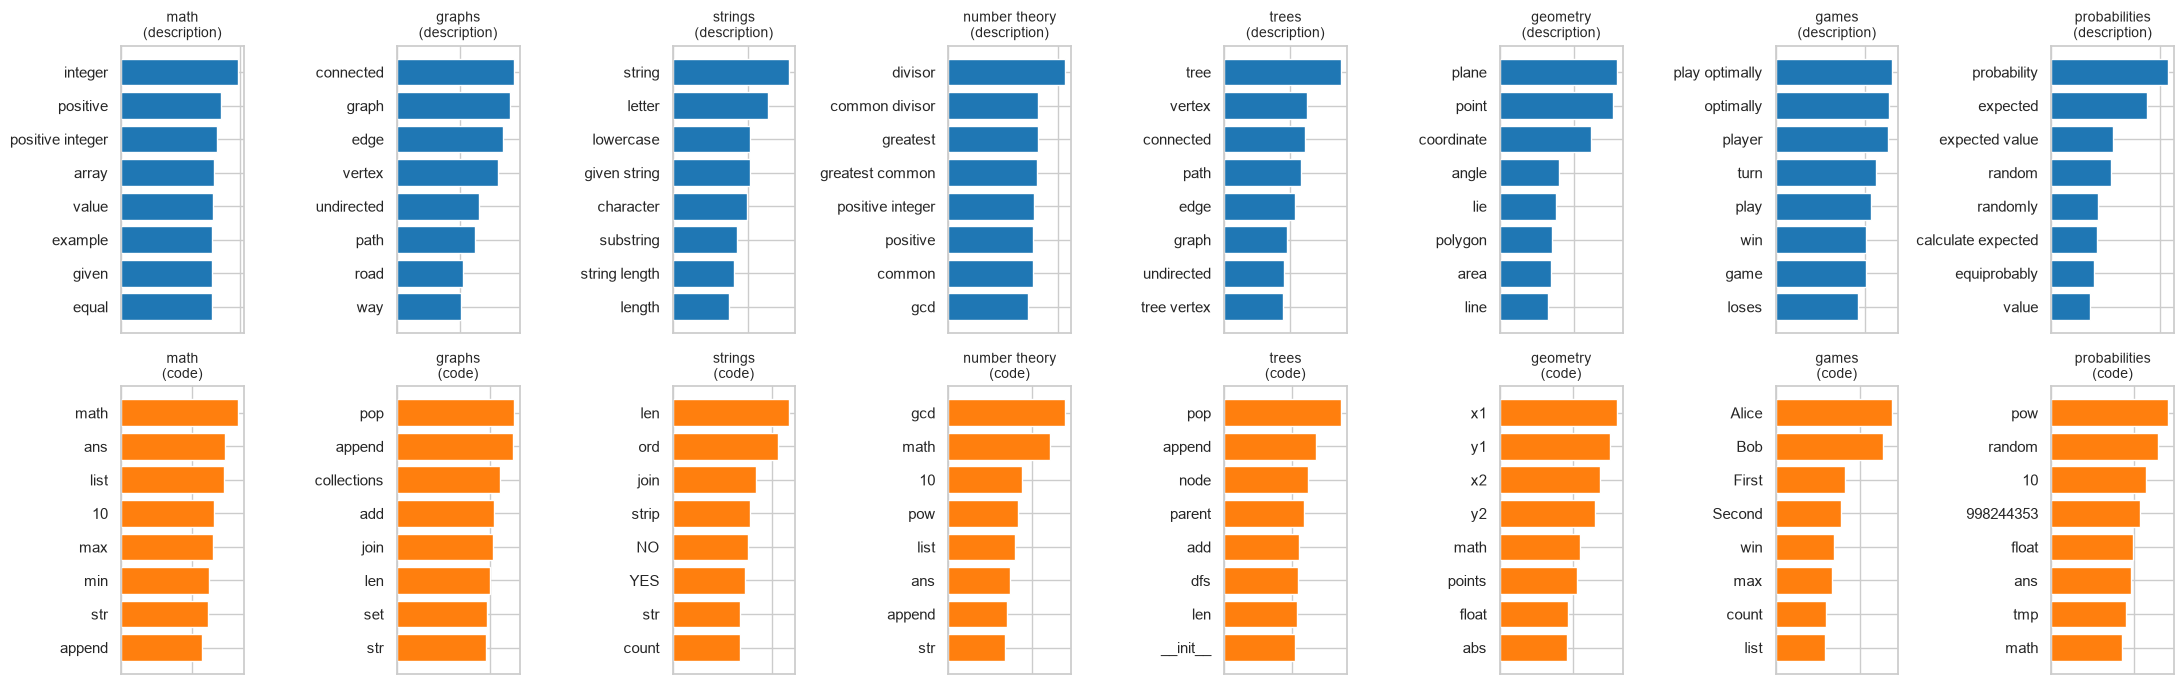

In [17]:
# Vue graphique : les 8 termes les plus caractéristiques de chaque tag, description vs code
fig, axes = plt.subplots(2, len(TARGET_TAGS), figsize=(22, 7))
for row, (source, scores) in enumerate({"description": desc_scores, "code": code_scores}.items()):
    for ax, tag in zip(axes[row], TARGET_TAGS):
        top = scores.loc[tag].nlargest(8)[::-1]
        ax.barh(top.index, top.values, color="tab:blue" if row == 0 else "tab:orange")
        ax.set_title(f"{tag}\n({source})", fontsize=10)
        ax.tick_params(axis="x", labelbottom=False)
plt.tight_layout()
plt.show()

## 5. Constats

**Nettoyage**
- 4 982 → **4 834** exemples : 17 énoncés en russe retirés, 131 quasi-doublons retirés (109 groupes, dont un groupe de 12
  variantes du problème des « regular bracket sequences »).
- Les exemples retirés d'un même groupe portent souvent des tags différents : on perd un peu de signal, mais on supprime
  le risque de fuite train/test.

**Embeddings** (`all-mpnet-base-v2`, 768 dimensions)
- 78 s sur GPU Apple (mps) pour 4 834 textes, puis rechargés depuis `data/embeddings/all-mpnet-base-v2__prob_desc_description.npz` (cache vérifié
  sur les `sample_id` et le nom du modèle).
- Seuls 2,9 % des énoncés dépassent 384 tokens et sont tronqués.

**Topics BERTopic**
- 61 topics, mais **35 % d'outliers** (topic -1) : HDBSCAN ne regroupe qu'une partie des énoncés.
- Les topics capturent surtout l'**habillage narratif** des énoncés (routes/villes, cartes/joueurs, magasins/pièces,
  monstres…) plutôt que la notion algorithmique sous-jacente.
- Ça fonctionne bien quand le vocabulaire de l'histoire coïncide avec le tag :
  - `strings` : 68 % des exemples dans un seul topic (lift 6,6) ;
  - `trees` : 52 % dans le topic « tree / vertices » (lift 8,7), qu'il partage avec `graphs` ;
  - `games` : lift 19,9 dans le topic « cards / player / game » ;
  - `number theory` : lift 10 dans le topic « gcd / divisor » ;
  - `geometry` : lift 9,7 dans le topic « points / segments ».
- Ça échoue pour les tags **conceptuels** : `math` (27 topics pour couvrir 50 % du tag) et `probabilities`
  (22 topics, 46 % en outliers). Le mot « probability » est rare ; c'est la structure du problème qui compte.
- La projection 2D le confirme : îlots nets pour `strings` (en bas) et `graphs` / `trees` (à droite), `math` diffus partout.

**TF-IDF par tag (description et code)**
- La version naïve (9 documents de classe) fait surtout ressortir des mots fréquents et génériques (« number », « array », « given »).
  La version retenue (présence binaire × IDF sur les exercices) donne des termes nettement plus discriminants.
- La **lemmatisation** de la description fusionne les variantes d'un même mot (*string* / *strings*, *vertex* / *vertices*) :
  chaque place du classement porte un concept distinct.
- **Description** : 7 tags sur 8 ont un vocabulaire propre.
  - `number theory` : *divisor, greatest common, gcd, prime, divisible*
  - `probabilities` : *probability, expected value, random, equiprobably*
  - `games` : *play optimally, player, turns, loses*
  - `geometry` : *plane, point, coordinate, angle, polygon*
  - `trees` : *tree, root, rooted, node, simple path*
  - `graphs` : *connected, graph, edge, vertex, undirected*
  - `strings` : *letter, lowercase, character, substring*
- **`math` n'a pas de vocabulaire propre dans l'énoncé** (*integer, positive, array, sum, equal* : des mots génériques). C'est la confirmation
  lexicale de sa difficulté.
- **Code** : la solution révèle la technique utilisée.
  - `math` → module `math`, `gcd`, `pow`
  - `number theory` → `gcd`, `pow`, `prime`, `sqrt`
  - `probabilities` → `998244353`, `pow` (inverse modulaire), `mod`, `random`, `float`
  - `graphs` → `deque`, `visited`, `edges`, `stack`
  - `trees` → `node`, `parent`, `dfs`, `root`, `__init__` (classe de nœud)
  - `geometry` → `x1`, `y1`, `pi`, `sqrt`, `abs`
  - `games` → `Alice`, `Bob`, `First`, `Second` : les chaînes affichées, c'est-à-dire le nom du gagnant attendu en sortie
  - `strings` → `ord`, `join`, `26` (taille de l'alphabet)
- `graphs` et `trees` partagent `pop`, `append` et `collections` (parcours BFS/DFS), ce qui explique leur forte co-occurrence et
  leurs confusions.
- Ces termes sont **exactement le type de signal qu'un embedding moyenné dilue** : c'est un argument fort pour tester un bloc
  TF-IDF sur le code (et, dans une moindre mesure, sur la description) dans l'ablation du notebook 05.

**Implications pour la classification**
- Les embeddings Sentence-BERT portent un signal réel pour 5 tags sur 8 : ce sont de bonnes features d'entrée pour un
  classifieur supervisé, à comparer à la baseline TF-IDF.
- Le clustering non supervisé seul ne suffit pas comme classifieur : il faut de la supervision, et le **code source**
  sera probablement nécessaire pour `math` et `probabilities` (imports `fractions`, modulo 998244353, `pow(x, mod - 2, mod)`…).